# 01 – Exploratory Data Analysis

MIT-BIH heartbeat dataset (Kachuee et al., 2018): each row is one heartbeat, 187 samples at 125 Hz, normalized to [0, 1], plus a class label (N, S, V, F, Q).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_mitbih, CLASS_NAMES

FIG_DIR = "../results/figures"
FS = 125  # sampling frequency (Hz)
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # N, S, V, F, Q
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12})

## 1. Load data

In [2]:
X_train, y_train = load_mitbih("train")
X_test, y_test = load_mitbih("test")

print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)

Train: (87554, 187) (87554,)
Test:  (21892, 187) (21892,)


## 2. Class distribution

The test set is only used here to report its class counts; it is not used for any modelling decision.

In [3]:
def class_counts(y):
    return pd.Series(y).value_counts().reindex(range(len(CLASS_NAMES)), fill_value=0)

dist = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": class_counts(y_train).values,
    "test": class_counts(y_test).values,
})
dist["train_%"] = (dist["train"] / dist["train"].sum() * 100).round(2)
dist["test_%"] = (dist["test"] / dist["test"].sum() * 100).round(2)
dist.to_csv("../results/metrics/class_distribution.csv", index=False)
dist

,class,train,test,train_%,test_%
0,N,72471,18118,82.77,82.76
1,S,2223,556,2.54,2.54
2,V,5788,1448,6.61,6.61
3,F,641,162,0.73,0.74
4,Q,6431,1608,7.35,7.35


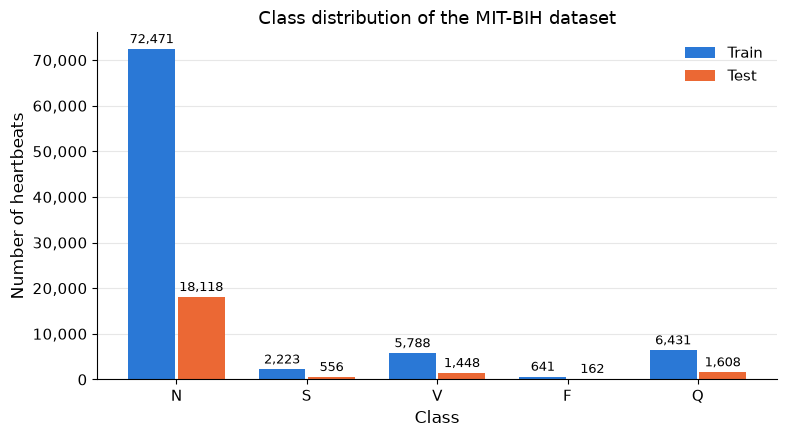

In [4]:
x = np.arange(len(CLASS_NAMES))
width = 0.36
offset = 0.19  # slightly larger than width / 2 to leave a small gap between bars

fig, ax = plt.subplots(figsize=(8, 4.5))
bars_tr = ax.bar(x - offset, dist["train"], width, label="Train", color="#2a78d6")
bars_te = ax.bar(x + offset, dist["test"], width, label="Test", color="#eb6834")

for bars in (bars_tr, bars_te):
    ax.bar_label(bars, labels=[f"{v:,}" for v in bars.datavalues], padding=2, fontsize=9)

ax.set_xticks(x, CLASS_NAMES)
ax.set_xlabel("Class")
ax.set_ylabel("Number of heartbeats")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Class distribution of the MIT-BIH dataset")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(f"{FIG_DIR}/class_distribution.png", dpi=200)
plt.show()

The dataset is highly imbalanced: about 83% of the beats are normal (N), while the fusion class (F) is below 1%. A model that always predicts N would already reach ~83% accuracy, so macro F1-score is used as the main metric.

## 3. Example heartbeats per class

Three randomly selected training beats from each class (one column per class). Each beat is 187 samples (about 1.5 s at 125 Hz) and starts at an R-peak; shorter beats are zero-padded at the end.

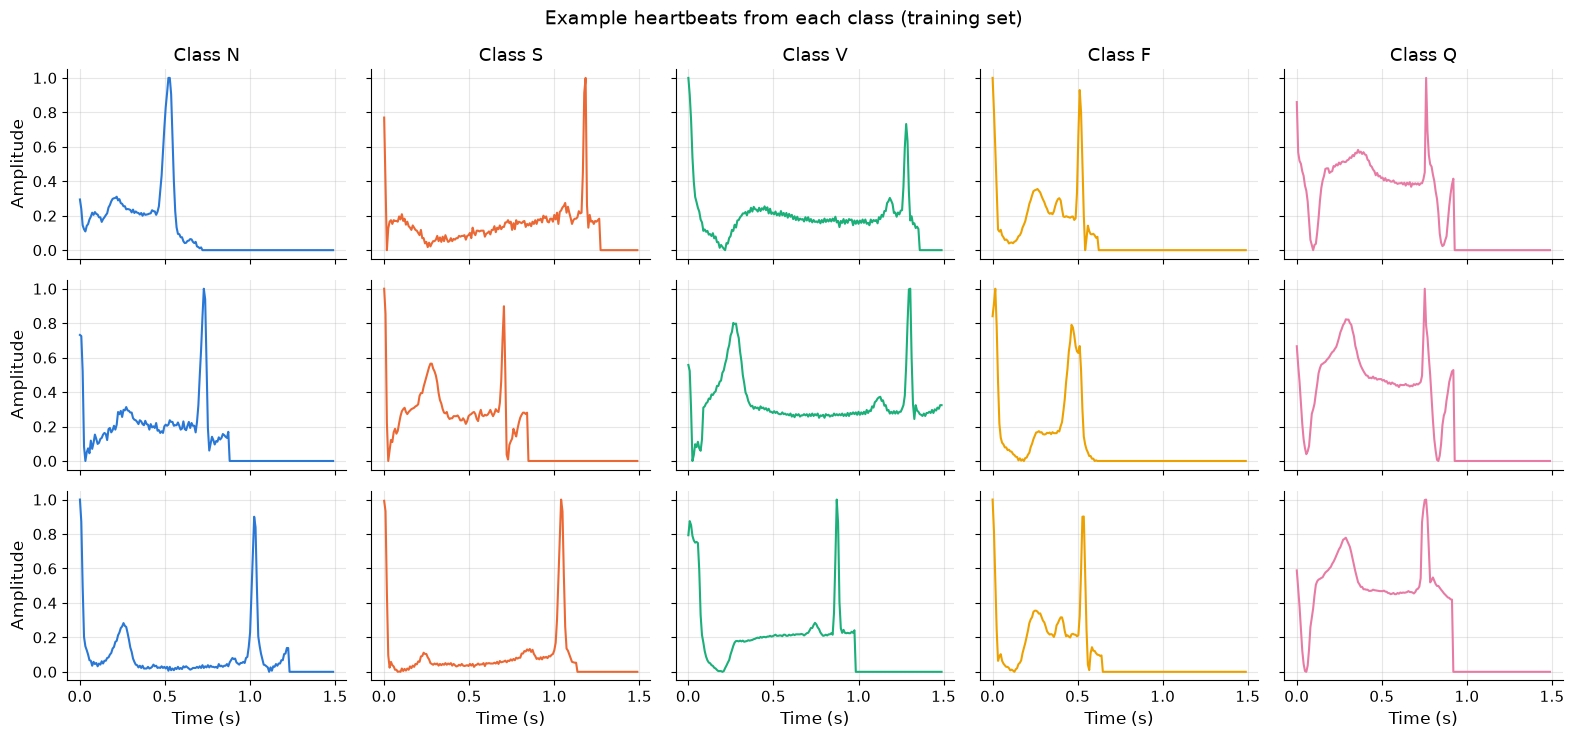

In [5]:
rng = np.random.default_rng(42)
n_examples = 3
t = np.arange(X_train.shape[1]) / FS

fig, axes = plt.subplots(n_examples, len(CLASS_NAMES), figsize=(16, 7.5), sharex=True, sharey=True)
for c in range(len(CLASS_NAMES)):
    idx = rng.choice(np.where(y_train == c)[0], size=n_examples, replace=False)
    for row, i in enumerate(idx):
        ax = axes[row, c]
        ax.plot(t, X_train[i], color=CLASS_COLORS[c], linewidth=1.5)
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0, c].set_title(f"Class {CLASS_NAMES[c]}")
    axes[-1, c].set_xlabel("Time (s)")
for row in range(n_examples):
    axes[row, 0].set_ylabel("Amplitude")

fig.suptitle("Example heartbeats from each class (training set)", fontsize=14)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/example_beats.png", dpi=200)
plt.show()

## 4. Mean heartbeat per class

Mean signal of each class over the training set, with a ±1 standard deviation band. The zero padding is included in the average, so the mean decreases towards the end of the window.

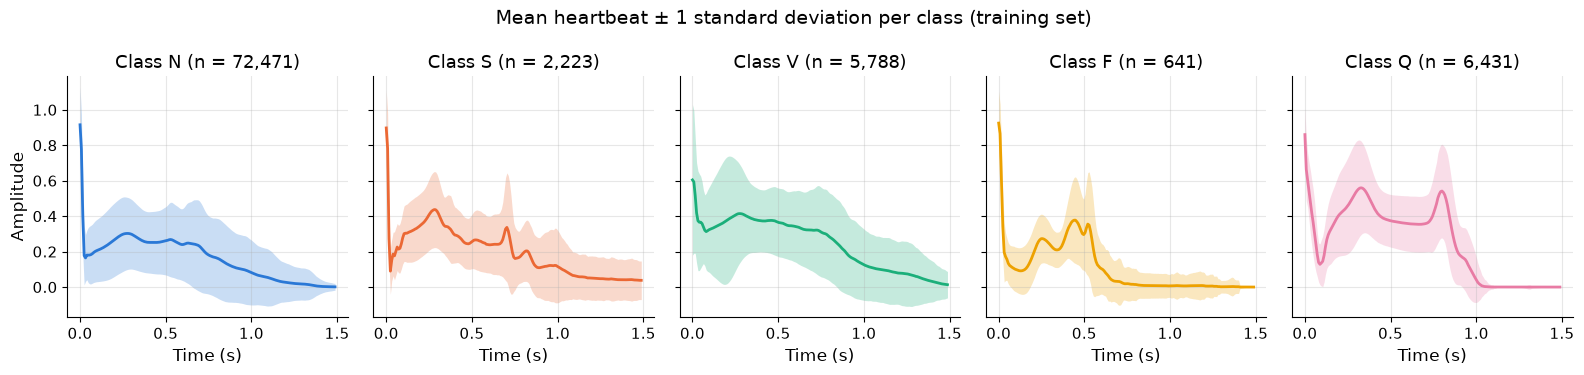

In [6]:
fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(16, 3.8), sharey=True)
for c, ax in enumerate(axes):
    beats = X_train[y_train == c]
    mean, std = beats.mean(axis=0), beats.std(axis=0)
    ax.fill_between(t, mean - std, mean + std, color=CLASS_COLORS[c], alpha=0.25, linewidth=0)
    ax.plot(t, mean, color=CLASS_COLORS[c], linewidth=2)
    ax.set_title(f"Class {CLASS_NAMES[c]} (n = {len(beats):,})")
    ax.set_xlabel("Time (s)")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Amplitude")

fig.suptitle("Mean heartbeat ± 1 standard deviation per class (training set)", fontsize=14)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/mean_beats.png", dpi=200)
plt.show()

## 5. Data quality checks

Missing values, value range, empty or constant beats and duplicate rows. Exact train–test duplicates are also checked, since they would leak test information into training.

In [7]:
def quality_report(X):
    return {
        "missing": int(np.isnan(X).sum()),
        "infinite": int(np.isinf(X).sum()),
        "min": float(X.min()),
        "max": float(X.max()),
        "all_zero_beats": int((X.max(axis=1) == 0).sum()),
        "constant_beats": int((X.std(axis=1) == 0).sum()),
        "duplicate_beats": int(pd.DataFrame(X).duplicated().sum()),
    }

quality = pd.DataFrame({"train": quality_report(X_train), "test": quality_report(X_test)})

train_rows = set(map(bytes, X_train))
n_overlap = sum(bytes(row) in train_rows for row in X_test)
print("Exact train-test duplicates:", n_overlap)
quality

Exact train-test duplicates: 0


,train,test
missing,0.0,0.0
infinite,0.0,0.0
min,0.0,0.0
max,1.0,1.0
all_zero_beats,0.0,0.0
constant_beats,0.0,0.0
duplicate_beats,0.0,0.0


Beats have different lengths and are zero-padded to 187 samples. The effective length (index of the last non-zero sample) is summarized per class below.

In [8]:
def effective_length(X):
    nonzero = X > 0
    return X.shape[1] - np.argmax(nonzero[:, ::-1], axis=1)

lengths = pd.DataFrame({"class": np.array(CLASS_NAMES)[y_train], "length": effective_length(X_train)})
length_stats = lengths.groupby("class", sort=False)["length"].describe()[["mean", "std", "min", "50%", "max"]]
length_stats["mean_seconds"] = length_stats["mean"] / FS
length_stats.round(2).to_csv("../results/metrics/beat_length_stats.csv")
length_stats.round(2)

,mean,std,min,50%,max,mean_seconds
class,,,,,,
N,110.81,27.18,17.0,106.0,187.0,0.89
S,113.91,39.24,22.0,107.0,187.0,0.91
V,118.17,34.91,27.0,114.0,187.0,0.95
F,78.83,13.92,29.0,78.0,187.0,0.63
Q,118.28,9.74,31.0,120.0,183.0,0.95


## 6. Train / validation split

20% of the official training set is held out as a stratified validation set (`random_state=42`). All model selection is done on this validation set; the test set is only used for the final evaluation.

In [9]:
from src.data import split_train_val

X_tr, X_val, y_tr, y_val = split_train_val(X_train, y_train)
print("Train:     ", X_tr.shape)
print("Validation:", X_val.shape)

split_dist = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": class_counts(y_tr).values,
    "validation": class_counts(y_val).values,
    "test": class_counts(y_test).values,
})
for col in ["train", "validation", "test"]:
    split_dist[f"{col}_%"] = (split_dist[col] / split_dist[col].sum() * 100).round(2)
split_dist.to_csv("../results/metrics/split_distribution.csv", index=False)
split_dist

Train:     

 (70043, 187)
Validation: (17511, 187)


,class,train,validation,test,train_%,validation_%,test_%
0,N,57977,14494,18118,82.77,82.77,82.76
1,S,1778,445,556,2.54,2.54,2.54
2,V,4630,1158,1448,6.61,6.61,6.61
3,F,513,128,162,0.73,0.73,0.74
4,Q,5145,1286,1608,7.35,7.34,7.35
